# Online Retail Case Study: Sales Analysis and A/B Test Proposal

## Project overview
This project looks at one year of transactions from a UK-based online retailer that sells mostly gift items, many of them to wholesale customers. I clean the raw data, explore when, where and through which products the store makes its money, and finish with a concrete A/B test proposal aimed at **increasing revenue**.

## Data
- **Source:** [UCI Machine Learning Repository, Online Retail data set](https://archive.ics.uci.edu/dataset/352/online+retail)
- **Period:** 1 December 2010 to 9 December 2011
- **Size:** 541,909 rows and 8 columns (invoice number, product code and description, quantity, invoice date, unit price, customer ID, country)
- **Limitation:** the data has selling prices but no costs, so I analyse **revenue**, not profit.

## Business question
*When, where and through which products does the store generate its revenue, and which A/B test could increase it?*

## Contents
1. Setup and data loading
2. Data cleaning
3. Exploratory analysis (KPIs, months, hours and weekdays, countries, products, customers, cancellations)
4. A/B test proposal
5. Conclusions, limitations and next steps

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statistics import NormalDist

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

In [2]:
# The Excel file is in the same folder as the notebook (see the README for the download link)
df_raw = pd.read_excel("Online Retail.xlsx")
print(df_raw.shape)
df_raw.info()

(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [3]:
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 2. Data cleaning

I work on a copy so the raw data stays untouched, and I record the number of rows after every step. That way I can show exactly what was removed and why.

### 2.1 Data types and duplicates
`CustomerID` is stored as a float only because it has missing values. It is an identifier, so I convert it to a nullable integer. I also make `InvoiceNo` and `StockCode` strings, because cancelled invoices start with the letter "C" and some product codes contain letters.

In [4]:
df = df_raw.copy()
log = [("Raw data", len(df))]

df["InvoiceNo"] = df["InvoiceNo"].astype("string")
df["StockCode"] = df["StockCode"].astype("string")
df["CustomerID"] = df["CustomerID"].astype("Int64")
df["Description"] = df["Description"].str.strip()

print("Missing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
log.append(("Duplicates removed", len(df)))

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1455
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Exact duplicate rows: 5268


### 2.2 Cancellations
Invoices starting with "C" are cancellations or returns. I do not want them to silently disappear when I filter on quantity, so I move them to their own data frame and come back to them in section 3.7.

In [5]:
is_cancel = df["InvoiceNo"].str.startswith("C")
df_cancel = df[is_cancel].copy()
df = df[~is_cancel].copy()
log.append(("Cancellation invoices moved out", len(df)))

print(f"Cancellation lines: {len(df_cancel):,} | Remaining sales lines: {len(df):,}")

Cancellation lines: 9,251 | Remaining sales lines: 527,390


### 2.3 Zero or negative quantities and prices
Before deleting anything I want to see what these rows are.

In [6]:
bad = df[(df["Quantity"] <= 0) | (df["UnitPrice"] <= 0)]
print("Suspicious lines:", len(bad))
print("  zero or negative price:   ", (df["UnitPrice"] <= 0).sum())
print("  zero or negative quantity:", (df["Quantity"] <= 0).sum())
print("  of which with no description:", bad["Description"].isna().sum())
bad.head(10)

Suspicious lines: 2512
  zero or negative price:    2512
  zero or negative quantity: 1336
  of which with no description: 1455


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,<NA>,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,<NA>,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,<NA>,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,<NA>,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,<NA>,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.00,<NA>,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.00,<NA>,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.00,<NA>,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.00,<NA>,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,<NA>,United Kingdom


Most of them have no description and a price of zero, which looks like stock adjustments, damaged goods and manual corrections rather than real sales. They carry no revenue, so I remove them.

In [7]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
log.append(("Non-positive quantity or price removed", len(df)))
print("Remaining:", len(df))

Remaining: 524878


### 2.4 Non-product stock codes
Real products have codes that start with five digits (for example `85123A`). Anything else is worth a look.

In [8]:
non_product = ~df["StockCode"].str.match(r"^\d{5}")
df.loc[non_product, "StockCode"].value_counts()

,count
StockCode,
POST,1126
DOT,706
M,316
C2,141
DCGSSGIRL,13
BANK CHARGES,12
DCGSSBOY,11
gift_0001_20,9
gift_0001_10,8


These are postage (`POST`), discounts and manual entries (`D`, `M`), bank charges, Amazon fees, gift vouchers and similar. They are not products, and keeping them would distort the product analysis, so I remove them.

In [9]:
df = df[~non_product].copy()
log.append(("Non-product codes removed", len(df)))
print("Remaining:", len(df))

Remaining: 522504


### 2.5 Derived columns

In [10]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Hour"] = df["InvoiceDate"].dt.hour
df["Weekday"] = df["InvoiceDate"].dt.day_name()
df["Month"] = df["InvoiceDate"].dt.to_period("M")

### 2.6 Outliers
A few lines are far larger than the rest. I look at the biggest ones first.

In [11]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID", "Revenue"]
df.nlargest(10, "Revenue")[cols]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446,"168,469.60"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346,"77,183.60"
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,2011-06-10 15:28:00,15098,"38,970.00"
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,2011-09-20 11:05:00,17450,"7,144.72"
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-01-11 12:55:00,15749,"6,539.40"
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,2011-04-18 13:20:00,15749,"6,539.40"
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,2011-10-27 12:11:00,14646,"4,992.00"
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,2011-01-11 12:55:00,15749,"4,921.50"
467804,576365,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,2011-11-14 17:55:00,<NA>,"4,781.60"
160542,550461,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,2011-04-18 13:20:00,15749,"4,632.00"


Two lines stand out by a huge margin (tens of thousands of units). A very large order is only suspicious if it did not really happen, so I check whether each of the biggest orders was cancelled afterwards by the same customer, for the same product and the same quantity.

In [12]:
outlier_index = []      # rows in df to remove
outlier_cancels = []    # the matching cancellation invoices

for idx, r in df.nlargest(5, "Quantity").iterrows():
    match = df_cancel[
        (df_cancel["CustomerID"] == r["CustomerID"]).fillna(False)
        & (df_cancel["StockCode"] == r["StockCode"]).fillna(False)
        & (df_cancel["Quantity"] == -r["Quantity"])
    ]
    cancelled_by = match["InvoiceNo"].tolist()
    print(f"{r['InvoiceNo']} | qty: {r['Quantity']:,} | revenue: {r['Revenue']:,.2f} | cancelled by: {cancelled_by}")
    if cancelled_by:
        outlier_index.append(idx)
        outlier_cancels.extend(cancelled_by)

581483 | qty: 80,995 | revenue: 168,469.60 | cancelled by: ['C581484']
541431 | qty: 74,215 | revenue: 77,183.60 | cancelled by: ['C541433']
573008 | qty: 4,800 | revenue: 1,008.00 | cancelled by: []
554868 | qty: 4,300 | revenue: 3,096.00 | cancelled by: []
544612 | qty: 3,906 | revenue: 3,202.92 | cancelled by: []


The two giant orders were cancelled right after they were placed, so they never generated real revenue. I remove them. The other large orders (a few thousand units at low prices) have no cancellation and are plausible wholesale purchases, so they stay.

In [13]:
df = df.drop(index=outlier_index)
n_outliers = len(outlier_index)
log.append(("Cancelled outlier orders removed", len(df)))
print(f"Removed {n_outliers} lines | Remaining: {len(df):,}")

Removed 2 lines | Remaining: 522,502


### 2.7 Cleaning summary

In [14]:
steps = pd.DataFrame(log, columns=["Step", "Rows remaining"])
steps["Rows removed"] = (steps["Rows remaining"].shift(1) - steps["Rows remaining"]).fillna(0).astype(int)
steps = steps[["Step", "Rows removed", "Rows remaining"]]

assert steps["Rows remaining"].iloc[-1] == len(df), "Row counts do not add up"
print(f"Rows kept: {len(df):,} of {len(df_raw):,} ({len(df) / len(df_raw):.1%})")
steps

Rows kept: 522,502 of 541,909 (96.4%)


,Step,Rows removed,Rows remaining
0,Raw data,0,541909
1,Duplicates removed,5268,536641
2,Cancellation invoices moved out,9251,527390
3,Non-positive quantity or price removed,2512,524878
4,Non-product codes removed,2374,522504
5,Cancelled outlier orders removed,2,522502


**Decision on missing customer IDs:** about a quarter of the remaining rows have no `CustomerID`. I keep them, because revenue by time, country and product does not need the customer. I only drop them in the customer-level analysis (section 3.6).

In [15]:
print("Rows without CustomerID:", f"{df['CustomerID'].isna().mean():.1%}")
df.info()

Rows without CustomerID: 25.1%
<class 'pandas.core.frame.DataFrame'>
Index: 522502 entries, 0 to 541908
Data columns (total 12 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    522502 non-null  string        
 1   StockCode    522502 non-null  string        
 2   Description  522502 non-null  object        
 3   Quantity     522502 non-null  int64         
 4   InvoiceDate  522502 non-null  datetime64[ns]
 5   UnitPrice    522502 non-null  float64       
 6   CustomerID   391148 non-null  Int64         
 7   Country      522502 non-null  object        
 8   Revenue      522502 non-null  float64       
 9   Hour         522502 non-null  int32         
 10  Weekday      522502 non-null  object        
 11  Month        522502 non-null  period[M]     
dtypes: Int64(1), datetime64[ns](1), float64(2), int32(1), int64(1), object(3), period[M](1), string(2)
memory usage: 50.3+ MB


In [16]:
df[["Quantity", "UnitPrice", "Revenue"]].describe()

,Quantity,UnitPrice,Revenue
count,"522,502.00","522,502.00","522,502.00"
mean,10.35,3.27,19.14
std,37.86,4.39,84.67
min,1.00,0.04,0.06
25%,1.00,1.25,3.90
50%,4.00,2.08,9.90
75%,12.00,4.13,17.70
max,"4,800.00",649.50,"38,970.00"


## 3. Exploratory analysis

### 3.1 Key figures

In [17]:
total_revenue = df["Revenue"].sum()
n_orders = df["InvoiceNo"].nunique()
n_customers = df["CustomerID"].nunique()
n_products = df["StockCode"].nunique()
n_countries = df["Country"].nunique()

# One row per order, used later for averages and for the A/B test
orders = df.groupby("InvoiceNo").agg(
    Revenue=("Revenue", "sum"),
    Date=("InvoiceDate", "min"),
    Country=("Country", "first"),
    CustomerID=("CustomerID", "first"),
)

print(f"Total revenue:          {total_revenue:,.0f}")
print(f"Orders:                 {n_orders:,}")
print(f"Identified customers:   {n_customers:,}")
print(f"Products sold:          {n_products:,}")
print(f"Countries:              {n_countries}")
print(f"Average order value:    {orders['Revenue'].mean():,.2f}")
print(f"Median order value:     {orders['Revenue'].median():,.2f}")

Total revenue:          10,001,168
Orders:                 19,771
Identified customers:   4,333
Products sold:          3,899
Countries:              38
Average order value:    505.85
Median order value:     302.20


The average order is much larger than the median order. That tells me a small number of very large baskets pull the average up, which matters for the A/B test in section 4.

### 3.2 Revenue by month
The data stops on 9 December 2011, so the last month is incomplete. I show it in grey and leave it out of the comparisons.

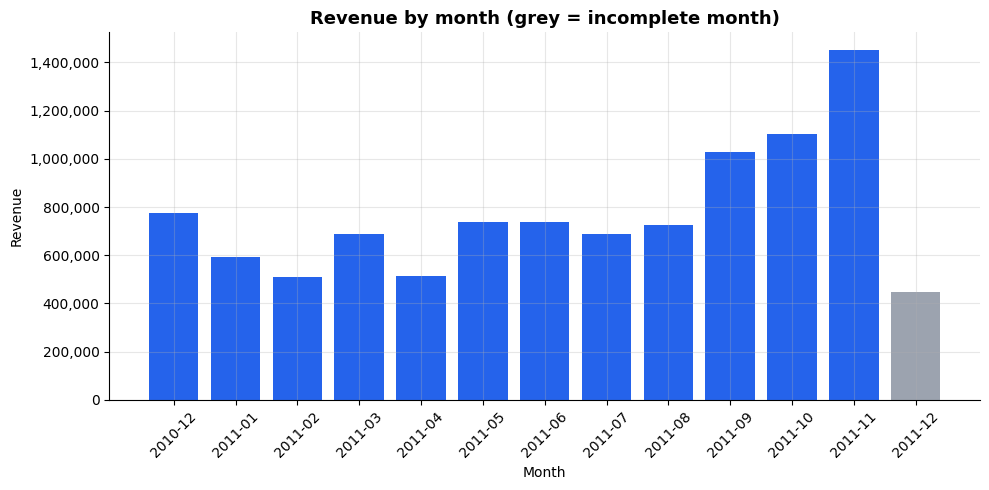

Best full month: 2011-11 with 1,452,113 (15.2% of the full months)
September to November together: 37.5% of the revenue of the full months


In [18]:
monthly = df.groupby("Month")["Revenue"].sum()

last_date = df["InvoiceDate"].max()
partial_month = last_date.to_period("M") if last_date.day < last_date.days_in_month else None
full = monthly.drop(partial_month) if partial_month is not None else monthly

colors = ["#9ca3af" if m == partial_month else "#2563eb" for m in monthly.index]
fig, ax = plt.subplots()
ax.bar(monthly.index.astype(str), monthly.values, color=colors)
ax.set_title("Revenue by month (grey = incomplete month)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

best_month = full.idxmax()
q4_share = full[[m for m in full.index if m.month in (9, 10, 11)]].sum() / full.sum()
print(f"Best full month: {best_month} with {full.max():,.0f} ({full.max() / full.sum():.1%} of the full months)")
print(f"September to November together: {q4_share:.1%} of the revenue of the full months")

**Takeaway:** sales build up through the autumn and peak in November, which fits a gift retailer preparing for Christmas. Revenue is clearly seasonal, so any test has to account for the time of year.

### 3.3 Revenue by hour and weekday

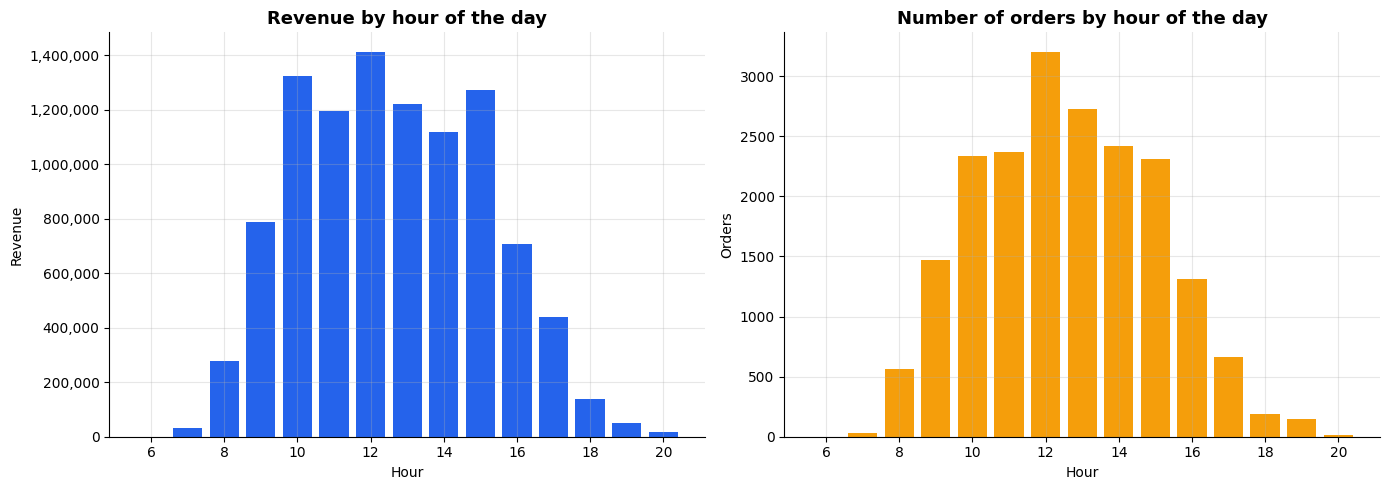

Peak revenue hour: 12:00
Revenue between 10:00 and 15:59: 75.5% of the total
Trading hours in the data: 6:00 to 20:59


In [19]:
hourly = df.groupby("Hour").agg(Revenue=("Revenue", "sum"), Orders=("InvoiceNo", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(hourly.index, hourly["Revenue"], color="#2563eb")
axes[0].set_title("Revenue by hour of the day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Revenue")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
axes[1].bar(hourly.index, hourly["Orders"], color="#f59e0b")
axes[1].set_title("Number of orders by hour of the day")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Orders")
plt.tight_layout()
plt.show()

peak_hour = hourly["Revenue"].idxmax()
midday_share = hourly.loc[10:15, "Revenue"].sum() / hourly["Revenue"].sum()
print(f"Peak revenue hour: {peak_hour}:00")
print(f"Revenue between 10:00 and 15:59: {midday_share:.1%} of the total")
print(f"Trading hours in the data: {hourly.index.min()}:00 to {hourly.index.max()}:59")

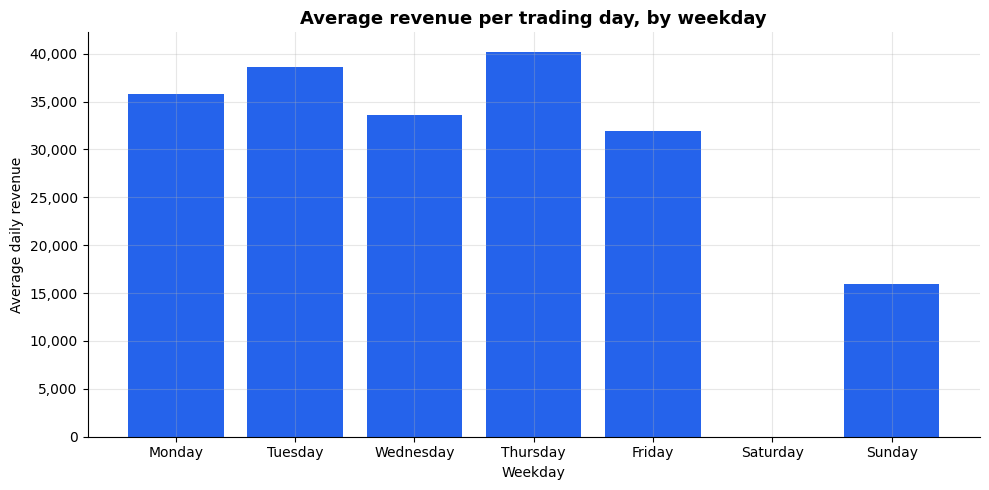

Weekdays with no transactions at all: ['Saturday']
Strongest weekday: Thursday (40,218 per day)


In [20]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Average revenue per trading day, so that weekdays with more days in the period are not favoured
daily = df.groupby(df["InvoiceDate"].dt.normalize())["Revenue"].sum()
by_weekday = daily.groupby(daily.index.day_name()).mean().reindex(weekday_order)

fig, ax = plt.subplots()
ax.bar(by_weekday.index, by_weekday.fillna(0), color="#2563eb")
ax.set_title("Average revenue per trading day, by weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("Average daily revenue")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
plt.tight_layout()
plt.show()

no_trade = by_weekday[by_weekday.isna()].index.tolist()
print("Weekdays with no transactions at all:", no_trade if no_trade else "none")
print(f"Strongest weekday: {by_weekday.idxmax()} ({by_weekday.max():,.0f} per day)")

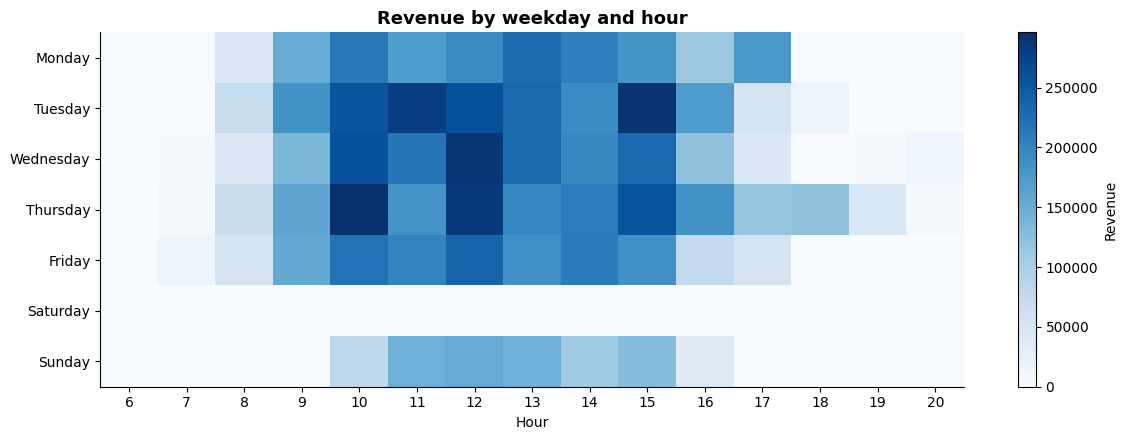

In [21]:
pivot = (df.pivot_table(index="Weekday", columns="Hour", values="Revenue", aggfunc="sum")
           .reindex(weekday_order).fillna(0))

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(pivot.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Revenue by weekday and hour")
ax.set_xlabel("Hour")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Revenue")
plt.tight_layout()
plt.show()

**Takeaway:** the business trades on weekdays during office hours, with revenue concentrated around midday. That pattern, together with the large basket sizes, suggests that many of the buyers are other businesses rather than private shoppers. The quiet early-morning and late-afternoon hours are the natural place to try promotions, because there is spare demand to win.

### 3.4 Revenue by country

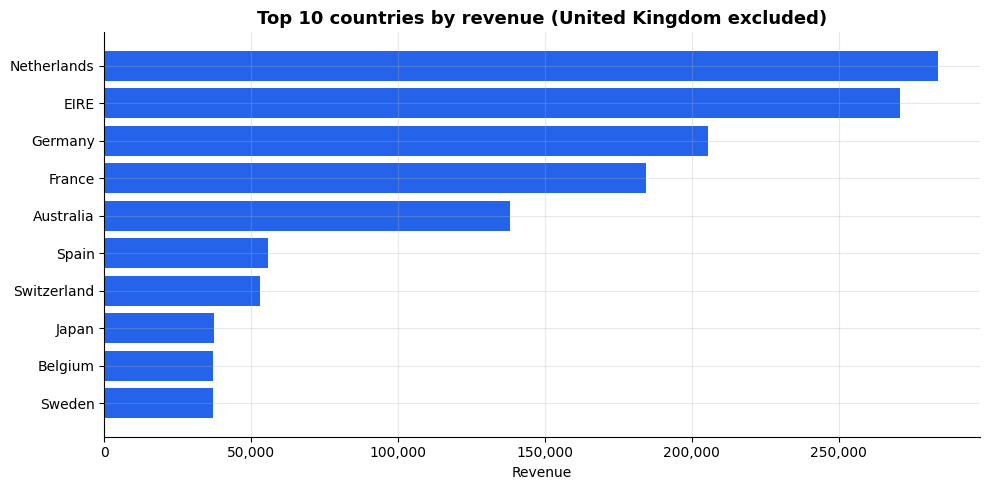

United Kingdom share of revenue: 84.8%
Top 10 other countries together: 13.0%


In [22]:
country = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country.get("United Kingdom", 0) / country.sum()
top_non_uk = country.drop("United Kingdom", errors="ignore").head(10)

fig, ax = plt.subplots()
ax.barh(top_non_uk.index[::-1], top_non_uk.values[::-1], color="#2563eb")
ax.set_title("Top 10 countries by revenue (United Kingdom excluded)")
ax.set_xlabel("Revenue")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
plt.tight_layout()
plt.show()

print(f"United Kingdom share of revenue: {uk_share:.1%}")
print(f"Top 10 other countries together: {top_non_uk.sum() / country.sum():.1%}")

**Takeaway:** the United Kingdom is by far the main market, so the rest of the world is a small slice of revenue. I leave the UK out of the chart on purpose, otherwise the other countries would be invisible. Overseas markets are a growth opportunity, but they should not be the first place to test.

### 3.5 Top products
I group by product description. A few stock codes share a description, which is fine for a ranking of this kind.

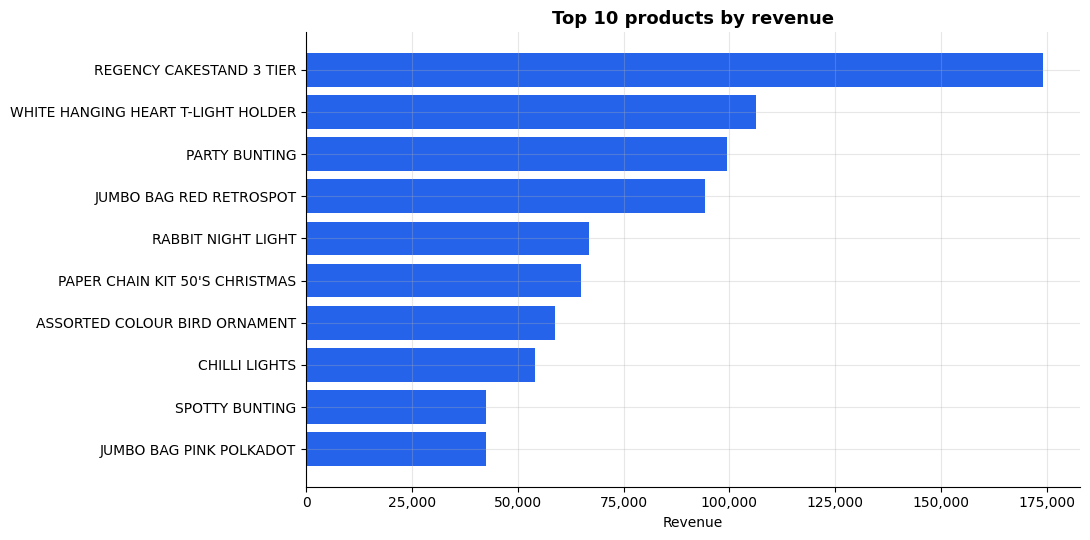

Top 10 products: 8.0% of revenue
Products needed to reach 50% of revenue: 256 of 3,993


In [23]:
products = (df.groupby("Description")
              .agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"))
              .sort_values("Revenue", ascending=False))
top10 = products.head(10)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(top10.index[::-1], top10["Revenue"][::-1], color="#2563eb")
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
plt.tight_layout()
plt.show()

cum_share = (products["Revenue"].cumsum() / products["Revenue"].sum()).values
n_half = int(np.searchsorted(cum_share, 0.5)) + 1
print(f"Top 10 products: {top10['Revenue'].sum() / total_revenue:.1%} of revenue")
print(f"Products needed to reach 50% of revenue: {n_half:,} of {len(products):,}")

**Takeaway:** revenue is spread over a very long tail of products. No single item dominates, so the top sellers matter, but the business does not depend on one product.

### 3.6 Customers
This section only uses rows with a known `CustomerID`.

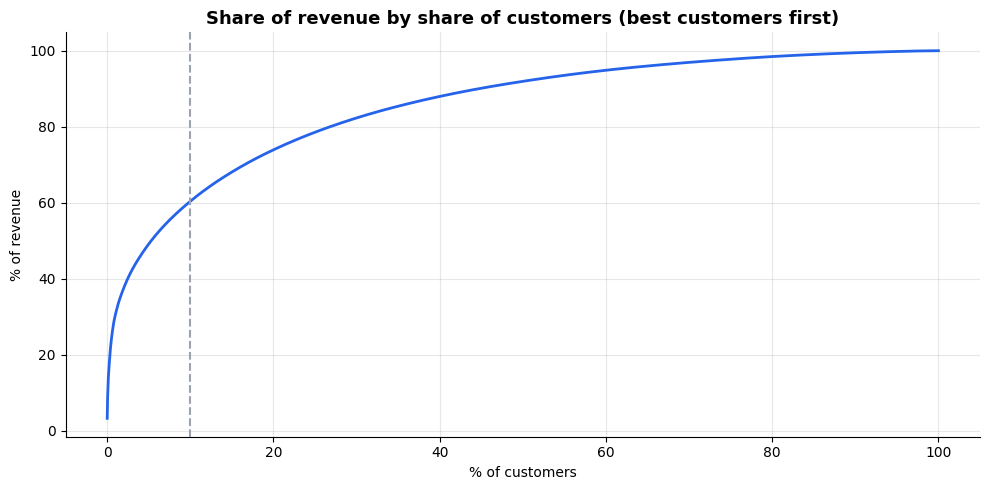

Top 10% of customers generate 60.3% of the revenue from identified customers
Customers who ordered more than once: 65.3%


In [24]:
known = df.dropna(subset=["CustomerID"])
cust_revenue = known.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
cust_orders = known.groupby("CustomerID")["InvoiceNo"].nunique()

top_n = max(1, int(len(cust_revenue) * 0.10))
top10_share = cust_revenue.head(top_n).sum() / cust_revenue.sum()
repeat_share = (cust_orders > 1).mean()

x = np.arange(1, len(cust_revenue) + 1) / len(cust_revenue) * 100
y = cust_revenue.cumsum() / cust_revenue.sum() * 100

fig, ax = plt.subplots()
ax.plot(x, y, color="#2563eb", linewidth=2)
ax.axvline(10, color="#9ca3af", linestyle="--")
ax.set_title("Share of revenue by share of customers (best customers first)")
ax.set_xlabel("% of customers")
ax.set_ylabel("% of revenue")
plt.tight_layout()
plt.show()

print(f"Top 10% of customers generate {top10_share:.1%} of the revenue from identified customers")
print(f"Customers who ordered more than once: {repeat_share:.1%}")

**Takeaway:** a minority of customers produce a large part of the revenue, and most customers come back. Retention of the best customers is therefore worth more than chasing one-off buyers.

### 3.7 Cancellations
I use the cancellation invoices I set aside in section 2.2. I exclude the two cancellations that belong to the outlier orders I removed, and the non-product codes, so the figures are comparable with the sales data.

In [25]:
cancel = df_cancel[
    df_cancel["StockCode"].str.match(r"^\d{5}")
    & ~df_cancel["InvoiceNo"].isin(outlier_cancels)
]
cancel_value = (cancel["Quantity"] * cancel["UnitPrice"]).abs().sum()
cancel_orders = cancel["InvoiceNo"].nunique()

print(f"Cancelled value:  {cancel_value:,.0f} ({cancel_value / total_revenue:.1%} of sales revenue)")
print(f"Cancellation invoices: {cancel_orders:,} ({cancel_orders / (n_orders + cancel_orders):.1%} of all invoices)")

Cancelled value:  230,248 (2.3% of sales revenue)
Cancellation invoices: 3,420 (14.7% of all invoices)


**Takeaway:** cancellations are a real but moderate leak. They are the natural guardrail metric for any promotion, because an offer that boosts sales but also boosts returns is not a win.

## 4. A/B test proposal

### Why this test
Three findings point in the same direction. Orders are large and uneven (the average order is well above the median), many buyers appear to be businesses, and demand is concentrated in a few hours and months. The lever I can actually move is **how much a customer puts in the basket**. The experiment I propose targets average order value directly.

### The experiment
**Hypothesis:** showing a free-delivery message above a basket threshold slightly higher than the typical order will make customers add items to reach it, and will increase revenue per order.

| Item | Proposal |
|---|---|
| Control (A) | Current checkout, no threshold message |
| Variant (B) | Banner in the basket: "Free delivery on orders over X", with X just above the median order |
| Unit of randomisation | The customer (so one person always sees the same version) |
| Primary metric | Revenue per order |
| Guardrail metrics | Number of orders, cancellation rate, delivery cost per order |
| Decision rule | Ship B if revenue per order rises by a statistically significant amount at the 5% level and the guardrails do not get worse |

The numbers below are calculated from this data set.

In [26]:
mu = orders["Revenue"].mean()
median_order = orders["Revenue"].median()
threshold = round(median_order * 1.2 / 10) * 10   # a bit above the typical order

# A handful of giant baskets would inflate the variance, so for the sample size
# calculation I cap order values at the 99th percentile (the same treatment I would use in the analysis)
cap = orders["Revenue"].quantile(0.99)
capped = orders["Revenue"].clip(upper=cap)
mu_c, sigma_c = capped.mean(), capped.std()

alpha, power, mde = 0.05, 0.80, 0.10   # 5% significance, 80% power, detect a 10% lift
z = NormalDist().inv_cdf
n_per_group = 2 * ((z(1 - alpha / 2) + z(power)) * sigma_c / (mde * mu_c)) ** 2

trading_days = df["InvoiceDate"].dt.normalize().nunique()
orders_per_day = n_orders / trading_days
days_needed = 2 * n_per_group / orders_per_day

print(f"Average order value: {mu:,.2f} | median: {median_order:,.2f}")
print(f"After capping at the 99th percentile ({cap:,.0f}): mean {mu_c:,.2f} | std {sigma_c:,.2f}")
print(f"Suggested threshold X: {threshold:,.0f}")
print(f"Orders needed per group to detect a {mde:.0%} lift: {n_per_group:,.0f}")
print(f"Average orders per trading day: {orders_per_day:,.0f}")
print(f"Estimated duration: {days_needed:,.0f} trading days (about {days_needed / 6:,.1f} weeks)")

Average order value: 505.85 | median: 302.20
After capping at the 99th percentile (4,394): mean 462.10 | std 643.23
Suggested threshold X: 360
Orders needed per group to detect a 10% lift: 3,042
Average orders per trading day: 65
Estimated duration: 94 trading days (about 15.6 weeks)


### How I would run it
- **Duration:** run it for at least the number of days above, rounded up to whole weeks so that every weekday is covered equally. Avoid starting during the November peak, since seasonality would confuse the result.
- **Analysis:** order values have a long right tail, so I would compare the groups on capped or log-transformed revenue and confirm the result with a bootstrap confidence interval.
- **Minimum effect:** I plan for a 10% lift. A smaller effect would need a much longer test, and a lift below 10% would probably not justify the cost of free delivery anyway.
- **Segments:** check the effect separately for the United Kingdom and for overseas customers, and for new versus returning customers.

### Limits of this proposal
This data set has orders, not website visits, so I cannot measure conversion rate and I use orders as the unit for the sample size. The delivery cost is not in the data, so the real profit effect of free delivery would have to be checked against it before rolling the offer out.

## 5. Conclusions

In [27]:
print("KEY FINDINGS")
print("-" * 60)
print(f"1. Data quality: {len(df_raw) - len(df):,} of {len(df_raw):,} rows ({1 - len(df) / len(df_raw):.1%}) were removed in cleaning.")
print(f"2. Seasonality: {best_month} was the best full month, and September to November account for {q4_share:.0%} of full-month revenue.")
print(f"3. Timing: {midday_share:.0%} of revenue falls between 10:00 and 15:59, with the peak at {peak_hour}:00.")
print(f"4. Geography: the United Kingdom generates {uk_share:.0%} of revenue.")
print(f"5. Customers: the top 10% of identified customers bring in {top10_share:.0%} of their revenue; {repeat_share:.0%} order more than once.")
print(f"6. Basket size: the average order ({mu:,.0f}) is well above the median ({median_order:,.0f}), so a few large baskets drive a lot of revenue.")

KEY FINDINGS
------------------------------------------------------------
1. Data quality: 19,407 of 541,909 rows (3.6%) were removed in cleaning.
2. Seasonality: 2011-11 was the best full month, and September to November account for 38% of full-month revenue.
3. Timing: 75% of revenue falls between 10:00 and 15:59, with the peak at 12:00.
4. Geography: the United Kingdom generates 85% of revenue.
5. Customers: the top 10% of identified customers bring in 60% of their revenue; 65% order more than once.
6. Basket size: the average order (506) is well above the median (302), so a few large baskets drive a lot of revenue.


### What I would recommend
1. **Test a free-delivery threshold** to raise average order value, as designed in section 4, outside the November peak.
2. **Protect the best customers.** A small group brings in a large part of the revenue, so retention offers for them are likely to pay off more than broad discounts.
3. **Use the quiet hours for promotions,** and keep the busy midday window free of anything that could slow the checkout.
4. **Plan stock and staffing around the autumn build-up** to the November peak.

### Limitations
- The data covers only one year of trading, so seasonal patterns cannot be confirmed over several years.
- There are no cost figures, so everything is about revenue and not profit.
- About a quarter of the rows have no customer ID, so the customer analysis covers only part of the sales.
- The A/B test is a design on paper. It has not been run, and the sample size uses orders as a stand-in for website visitors.

### Next steps
- Segment customers with an RFM analysis (recency, frequency, monetary value).
- Forecast monthly revenue to support stock planning.
- Add a dashboard (Power BI or Tableau) with the main charts.